# Trabalho 1 — Previsão de Doença Cardíaca (Heart Failure Prediction)
**Disciplina:** IN1038 — PUC-Rio
**Dataset:** [Heart Failure Prediction — fedesoriano (Kaggle)](https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)

**Objetivo:** prever se um paciente tem doença cardíaca (`HeartDisease` = 1) a partir de dados clínicos simples
(idade, pressão, colesterol, ECG, teste de esforço...).

**Roteiro**
1. Carga e dicionário de dados
2. Avaliação da base — vale a pena usar?
3. Sanitização
4. Análise descritiva e univariada
5. Análise bivariada (atributo × alvo)
6. Análise multivariada
7. Pré-processamento
8. Seleção / redução de atributos
9. Modelos supervisionados (Regressão Linear, Regressão Logística, SVM)
10. Avaliação no conjunto de teste
11. Conclusões

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif, RFE, RFECV, SelectFromModel
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             r2_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
FIGS = Path("figs")
FIGS.mkdir(exist_ok=True)

def salvar(nome):
    plt.savefig(FIGS / f"{nome}.png", bbox_inches="tight", dpi=150)

## 1. Carga e dicionário de dados

| Atributo | Descrição | Tipo |
|---|---|---|
| `Age` | Idade (anos) | numérico |
| `Sex` | Sexo (M/F) | categórico |
| `ChestPainType` | Tipo de dor no peito: TA (angina típica), ATA (angina atípica), NAP (dor não anginosa), ASY (assintomático) | categórico |
| `RestingBP` | Pressão arterial em repouso (mm Hg) | numérico |
| `Cholesterol` | Colesterol sérico (mg/dl) | numérico |
| `FastingBS` | Glicemia em jejum > 120 mg/dl (1 = sim) | binário |
| `RestingECG` | ECG em repouso: Normal, ST (anormalidade ST-T), LVH (hipertrofia ventricular esquerda) | categórico |
| `MaxHR` | Frequência cardíaca máxima atingida no teste de esforço | numérico |
| `ExerciseAngina` | Angina induzida por exercício (Y/N) | categórico |
| `Oldpeak` | Depressão do segmento ST induzida por exercício (mm) | numérico |
| `ST_Slope` | Inclinação do segmento ST no pico do exercício: Up, Flat, Down | categórico |
| `HeartDisease` | **Alvo** — 1 = doença cardíaca, 0 = normal | binário |

A base é a junção de 5 bases clássicas da UCI (Cleveland, Hungria, Suíça, Long Beach VA e Stalog), com as
duplicatas já removidas pelo autor.

In [2]:
df = pd.read_csv("data/heart.csv")
NUM = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
CAT = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]
TARGET = "HeartDisease"
print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


## 2. Avaliação da base — vale a pena usar?

Antes de investir na análise, checamos: quantidade de linhas, nulos, duplicatas e balanceamento do alvo.

Linhas x colunas: (918, 12)
Nulos (NaN): 0
Linhas duplicadas: 0

Zeros por coluna (suspeitos em atributos fisiológicos):
Age              0
RestingBP        1
Cholesterol    172
MaxHR            0
Oldpeak        368
dtype: int64


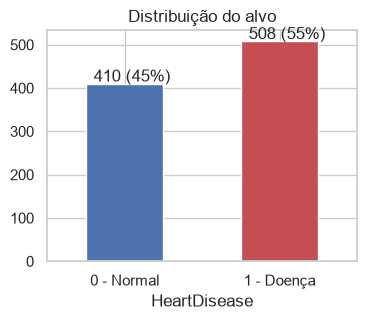

In [4]:
print("Linhas x colunas:", df.shape)
print("Nulos (NaN):", df.isna().sum().sum())
print("Linhas duplicadas:", df.duplicated().sum())
print("\nZeros por coluna (suspeitos em atributos fisiológicos):")
print((df[NUM] == 0).sum())

fig, ax = plt.subplots(figsize=(4, 3))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax, color=["#4c72b0", "#c44e52"])
ax.set_xticklabels(["0 - Normal", "1 - Doença"], rotation=0)
ax.set_title("Distribuição do alvo")
for p in ax.patches:
    ax.annotate(f"{p.get_height()} ({p.get_height()/len(df):.0%})", (p.get_x() + 0.05, p.get_height() + 5))
salvar("01_alvo")
plt.show()

**Veredito:** a base **vale a pena**.
- 918 pacientes e 11 atributos — pequena, mas ~3× maior que a Cleveland original (303), e suficiente para
  Regressão Logística e SVM se avaliarmos com **validação cruzada**.
- Alvo **balanceado** (~55% / 45%) → acurácia é uma métrica honesta (mas, sendo saúde, olharemos também o *recall*).
- Sem `NaN` e sem duplicatas.
- **Porém**: há valores **zero impossíveis** — `Cholesterol = 0` (172 pacientes!) e `RestingBP = 0` (1 paciente).
  Ninguém vivo tem colesterol ou pressão zero: são **dados faltantes disfarçados**. Tratamos isso na sanitização.

## 3. Sanitização

### 3.1 Zeros impossíveis

In [5]:
chol0 = df["Cholesterol"] == 0
print(f"Cholesterol = 0: {chol0.sum()} pacientes ({chol0.mean():.1%})")
print(f"Taxa de doença com Cholesterol = 0: {df.loc[chol0, TARGET].mean():.1%}")
print(f"Taxa de doença com Cholesterol > 0: {df.loc[~chol0, TARGET].mean():.1%}")
print()
print(df[df["RestingBP"] == 0])

Cholesterol = 0: 172 pacientes (18.7%)
Taxa de doença com Cholesterol = 0: 88.4%
Taxa de doença com Cholesterol > 0: 47.7%

     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
449   55   M           NAP          0            0          0     Normal   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
449    155              N      1.5     Flat             1  


**Achado importante:** 88% dos pacientes com colesterol "zero" têm doença cardíaca, contra 48% no restante.
Isso **não** é efeito biológico: os zeros vêm quase todos de um mesmo hospital de origem (a base suíça não mediu
colesterol), e essa base tinha muitos doentes. Ou seja, o "zero" carrega informação sobre **de onde veio o paciente**,
não sobre o colesterol dele.

Decisões:
- `RestingBP = 0` → 1 linha só: **removemos**.
- `Cholesterol = 0` → 19% da base, remover seria desperdício: **marcamos como `NaN` e imputamos pela mediana**
  (dentro do *pipeline*, usando só os dados de treino, para não vazar informação do teste).
  Não criamos uma flag "colesterol ausente", porque ela ensinaria ao modelo um artefato de coleta, e não medicina.

In [6]:
df = df[df["RestingBP"] != 0].copy()
df.loc[df["Cholesterol"] == 0, "Cholesterol"] = np.nan
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])

(917, 12)
Cholesterol    171
dtype: int64


### 3.2 Valores negativos e outliers
`Oldpeak` tem valores negativos. Clinicamente isso é possível (elevação do segmento ST em vez de depressão),
então mantemos. Abaixo, contamos outliers pelo critério do IQR (1,5 × IQR).

In [7]:
print("Oldpeak < 0:", (df["Oldpeak"] < 0).sum())

def outliers_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({c: {"outliers (IQR)": outliers_iqr(df[c].dropna()),
                  "min": df[c].min(), "max": df[c].max()} for c in NUM}).T

Oldpeak < 0: 13


,outliers (IQR),min,max
Age,0.0,28.0,77.0
RestingBP,27.0,80.0,200.0
Cholesterol,23.0,85.0,603.0
MaxHR,2.0,60.0,202.0
Oldpeak,16.0,-2.6,6.2


Os outliers estão dentro de faixas **clinicamente plausíveis** (pressão até 200, colesterol até 603, Oldpeak até 6,2):
são pacientes graves, não erros de digitação. Como esses casos extremos são justamente os mais informativos para
detectar doença, **mantemos os outliers**. A padronização (`StandardScaler`) reduz o impacto deles nos modelos.

## 4. Análise descritiva e univariada
### 4.1 Atributos numéricos

In [8]:
desc = df[NUM].describe().T
desc["assimetria"] = df[NUM].skew()
desc["curtose"] = df[NUM].kurt()
desc["shapiro p-valor"] = [stats.shapiro(df[c].dropna()).pvalue for c in NUM]
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,assimetria,curtose,shapiro p-valor
Age,917.0,53.509,9.438,28.0,47.00,54.0,60.0,77.0,-0.195,-0.389,0.0
RestingBP,917.0,132.541,18.000,80.0,120.00,130.0,140.0,200.0,0.607,0.792,0.0
Cholesterol,746.0,244.635,59.154,85.0,207.25,237.0,275.0,603.0,1.239,4.529,0.0
MaxHR,917.0,136.790,25.467,60.0,120.00,138.0,156.0,202.0,-0.142,-0.449,0.0
Oldpeak,917.0,0.887,1.067,-2.6,0.00,0.6,1.5,6.2,1.025,1.204,0.0


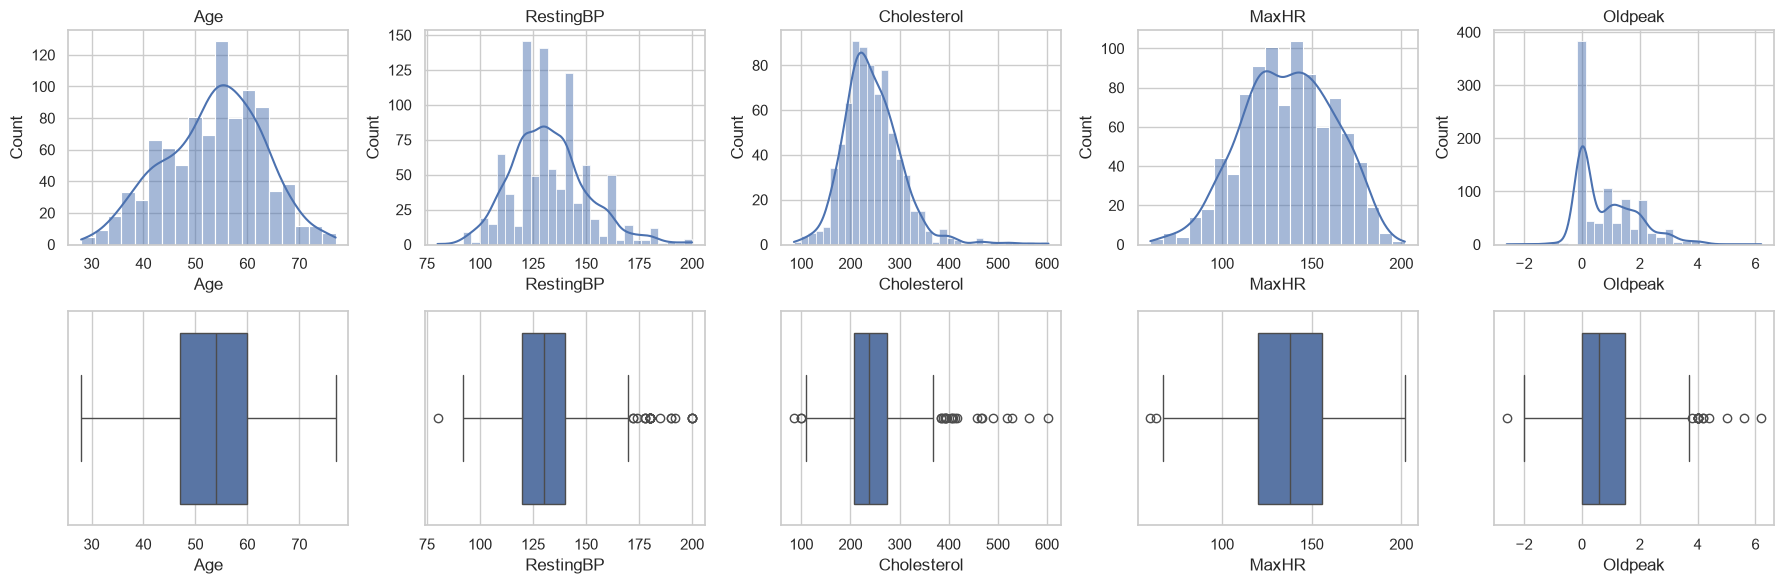

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for i, c in enumerate(NUM):
    sns.histplot(df[c], kde=True, ax=axes[0, i])
    sns.boxplot(x=df[c], ax=axes[1, i])
    axes[0, i].set_title(c)
plt.tight_layout()
salvar("02_univariada_numericas")
plt.show()

**Leitura:**
- **Nenhum atributo é normal** pelo teste de Shapiro-Wilk (p < 0,05). Por isso, na análise bivariada usamos
  testes **não paramétricos** (Mann-Whitney).
- `Age` e `MaxHR` são quase simétricos. `Cholesterol` (mesmo sem os zeros) e principalmente `Oldpeak` têm
  **cauda longa à direita**: a maioria dos pacientes tem Oldpeak perto de 0 e poucos têm valores altos.
- Pacientes de meia-idade (mediana 54 anos), o que é esperado para uma base de investigação cardíaca.

### 4.2 Atributos categóricos

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.flat, CAT):
    sns.countplot(x=df[c], ax=ax, order=df[c].value_counts().index)
    ax.set_title(c)
plt.tight_layout()
salvar("03_univariada_categoricas")
plt.show()

**Leitura:**
- **Base muito masculina** (~79% homens) → os resultados podem generalizar pior para mulheres.
- A dor no peito mais comum é **ASY (assintomático)** — à primeira vista estranho, mas típico: muitos cardiopatas
  não sentem a dor "clássica".
- `ST_Slope = Down` é raro (~7%): o modelo terá poucos exemplos dessa categoria.

## 5. Análise bivariada — cada atributo × doença
### 5.1 Numéricos × alvo (Mann-Whitney U)

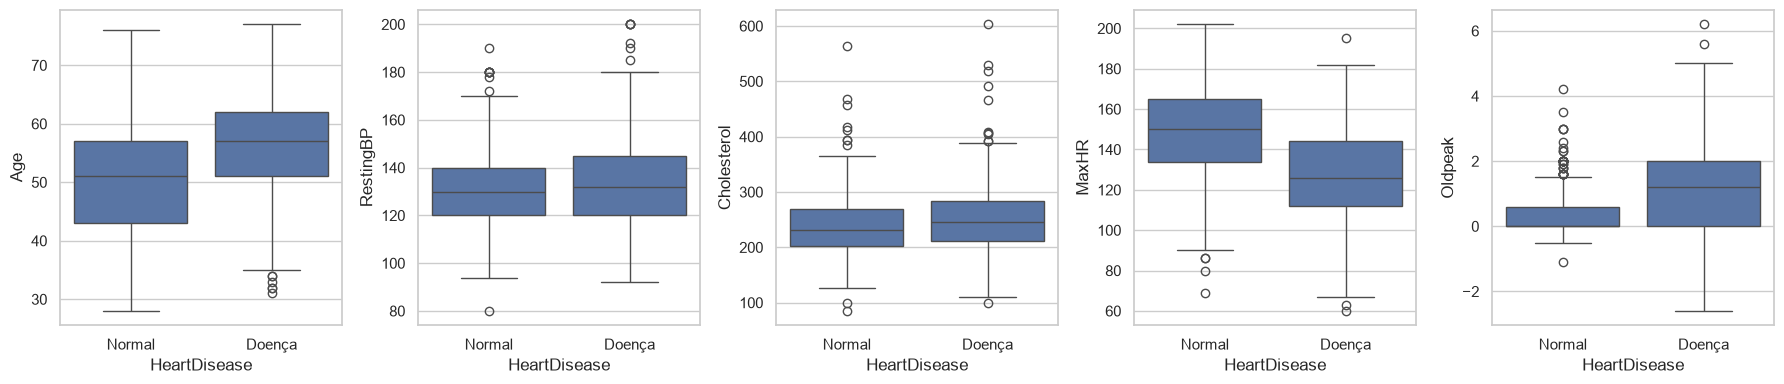

,mediana normal,mediana doença,p-valor Mann-Whitney
atributo,,,
Age,51.0,57.0,1.905061e-18
RestingBP,130.0,132.0,4.567880e-04
Cholesterol,231.5,246.0,1.713007e-03
MaxHR,150.0,126.0,1.075177e-34
Oldpeak,0.0,1.2,8.915674e-37


In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
linhas = []
for ax, c in zip(axes, NUM):
    sns.boxplot(data=df, x=TARGET, y=c, ax=ax)
    ax.set_xticklabels(["Normal", "Doença"])
    g0, g1 = df.loc[df[TARGET] == 0, c].dropna(), df.loc[df[TARGET] == 1, c].dropna()
    linhas.append({"atributo": c, "mediana normal": g0.median(), "mediana doença": g1.median(),
                   "p-valor Mann-Whitney": stats.mannwhitneyu(g0, g1).pvalue})
plt.tight_layout()
salvar("04_bivariada_numericas")
plt.show()
pd.DataFrame(linhas).set_index("atributo")

### 5.2 Categóricos × alvo (Qui-quadrado e V de Cramér)
O V de Cramér mede a **força** da associação (0 = nenhuma, 1 = total), enquanto o p-valor só diz se ela existe.

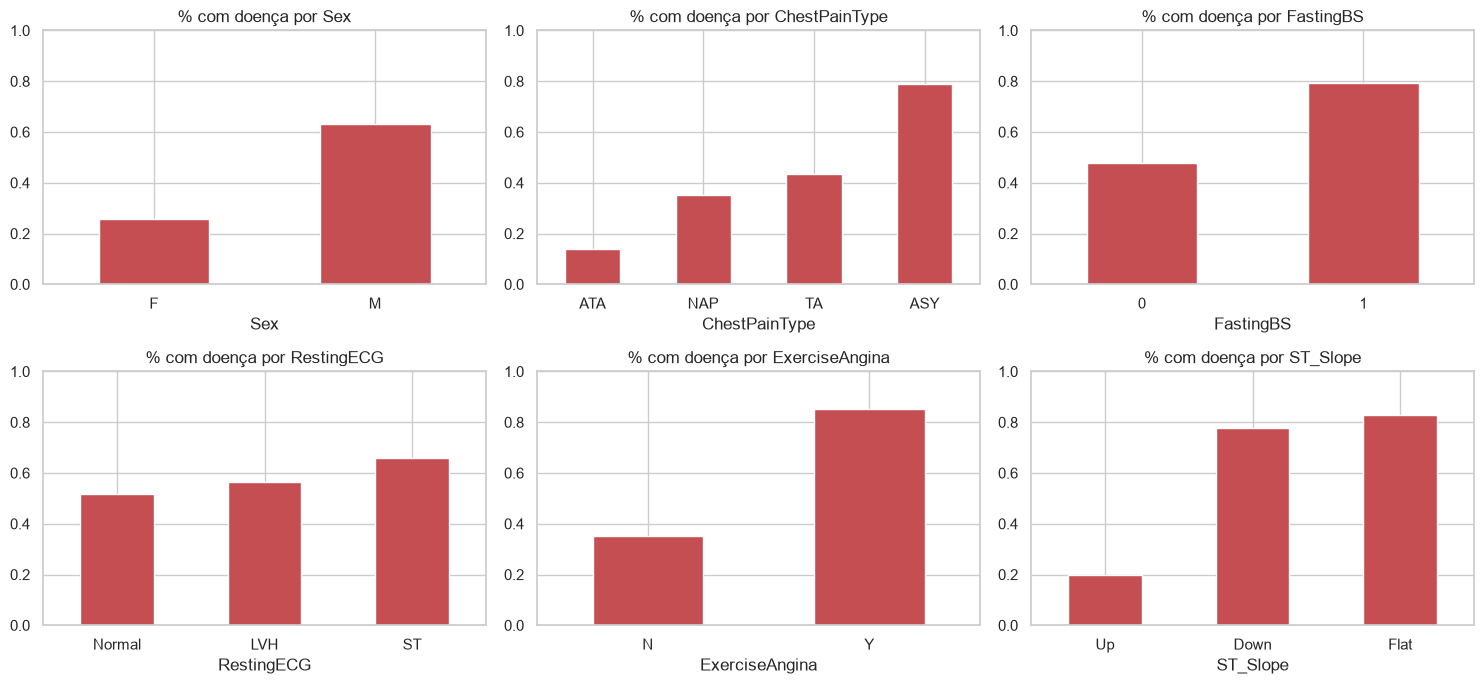

,p-valor qui²,V de Cramér
atributo,,
ST_Slope,0.0000,0.6223
ChestPainType,0.0000,0.5415
ExerciseAngina,0.0000,0.4933
Sex,0.0000,0.3024
FastingBS,0.0000,0.2654
RestingECG,0.0039,0.1099


In [ ]:
def cramers_v(tab):
    chi2 = stats.chi2_contingency(tab)[0]
    n = tab.values.sum()
    return np.sqrt(chi2 / (n * (min(tab.shape) - 1)))

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
linhas = []
for ax, c in zip(axes.flat, CAT):
    tab = pd.crosstab(df[c], df[TARGET])
    linhas.append({"atributo": c, "p-valor qui²": stats.chi2_contingency(tab)[1], "V de Cramér": cramers_v(tab)})
    (df.groupby(c)[TARGET].mean().sort_values()).plot.bar(ax=ax, color="#c44e52")
    ax.set_title(f"% com doença por {c}")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
salvar("05_bivariada_categoricas")
plt.show()
pd.DataFrame(linhas).set_index("atributo").sort_values("V de Cramér", ascending=False).round(4)

**Leitura (bivariada):**
- Os sinais mais fortes vêm do **teste de esforço**: `ST_Slope` (Flat/Down → maioria doente), `ExerciseAngina`
  (angina no exercício → maioria doente), `Oldpeak` alto e `MaxHR` baixo (quem não consegue acelerar o coração).
- `ChestPainType = ASY` tem a maior taxa de doença: o paciente **assintomático** é o mais doente — contraintuitivo,
  mas faz sentido clínico (isquemia silenciosa).
- `RestingBP` e `Cholesterol` têm p-valor < 0,05, mas a diferença é **pequena** (medianas de colesterol 232 vs 246;
  pressão 130 vs 132): com quase mil pacientes, até efeitos minúsculos ficam "significativos". `RestingECG` tem
  associação fraca (V = 0,11).
  O colesterol, famoso como "vilão", sozinho não é bom preditor nesta base.

## 6. Análise multivariada
### 6.1 Correlação
Fazemos *one-hot encoding* das categóricas para enxergar tudo numa mesma matriz (Spearman, por causa da não-normalidade).

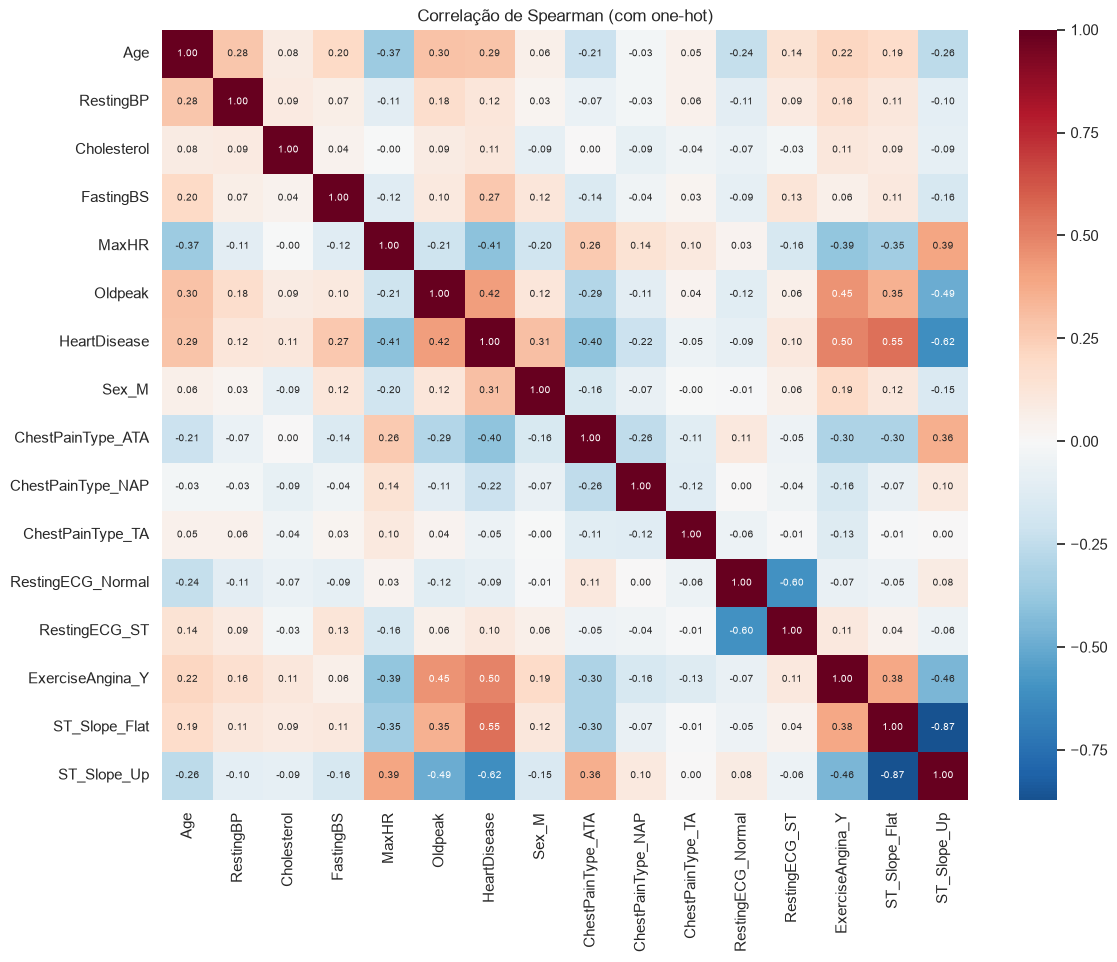

ST_Slope_Up         -0.622
ST_Slope_Flat        0.554
ExerciseAngina_Y     0.495
Oldpeak              0.419
MaxHR               -0.406
ChestPainType_ATA   -0.402
Sex_M                0.305
Age                  0.290
FastingBS            0.268
ChestPainType_NAP   -0.215
RestingBP            0.116
Cholesterol          0.115
RestingECG_ST        0.103
RestingECG_Normal   -0.092
ChestPainType_TA    -0.055
Name: HeartDisease, dtype: float64

In [ ]:
df_enc = pd.get_dummies(df, columns=["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"],
                        drop_first=True, dtype=int)
corr = df_enc.corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlação de Spearman (com one-hot)")
salvar("06_correlacao")
plt.show()

corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

### 6.2 Pairplot dos numéricos

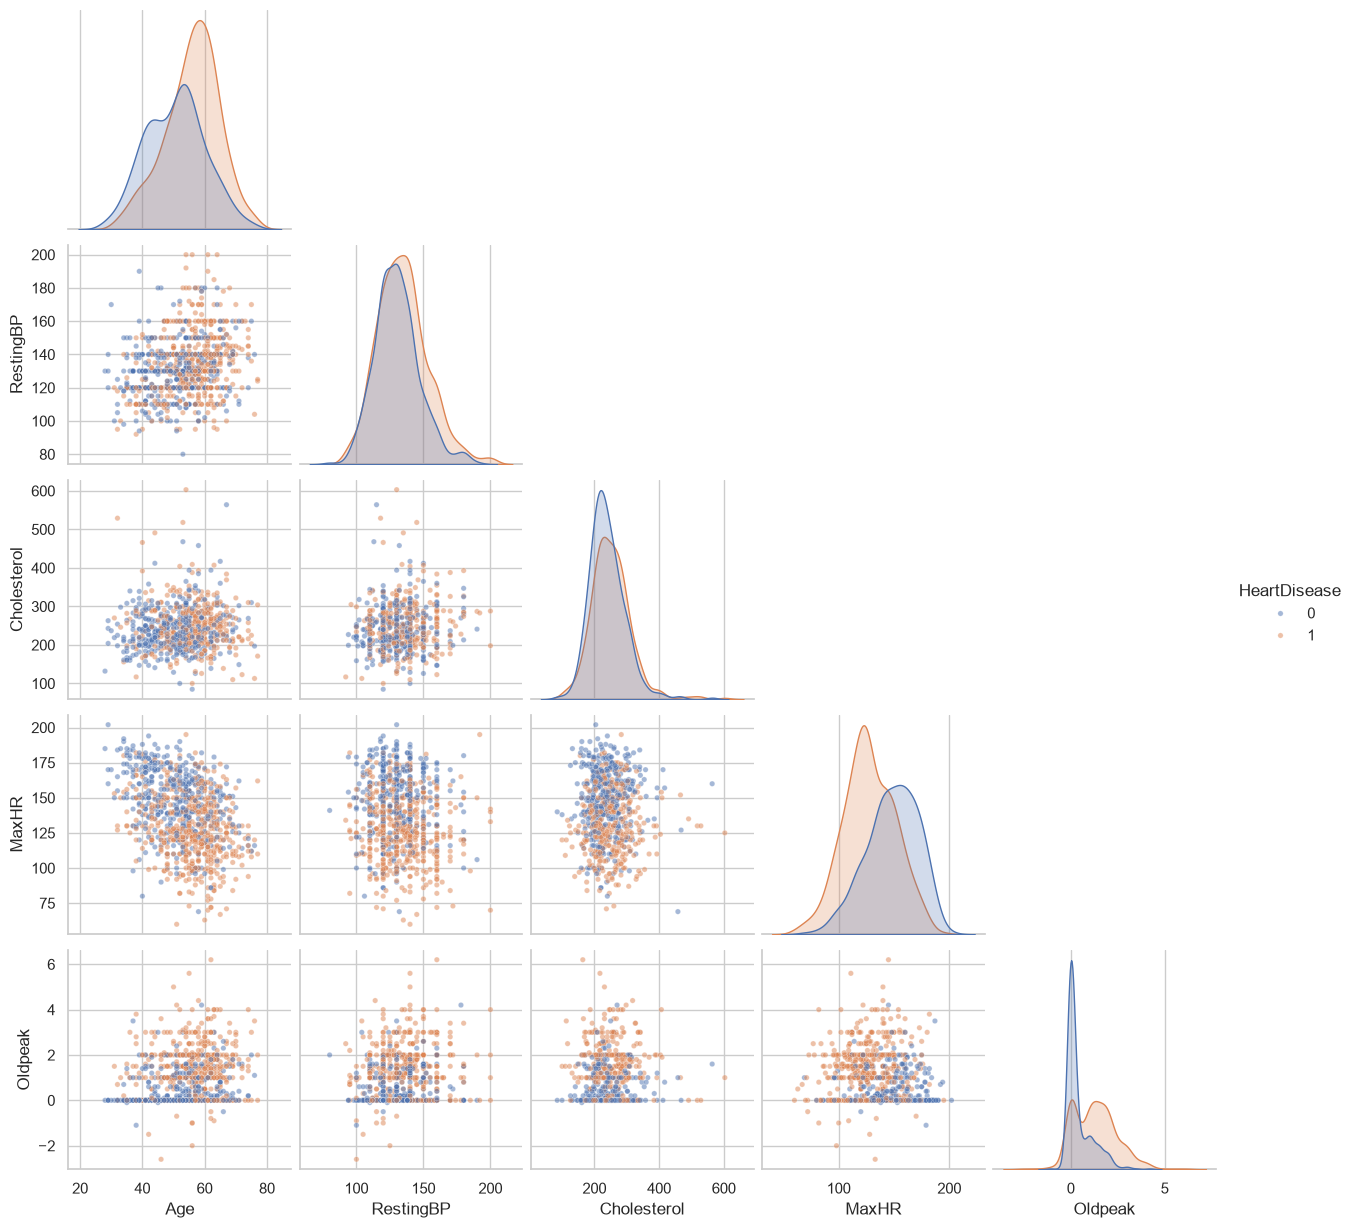

In [ ]:
g = sns.pairplot(df[NUM + [TARGET]], hue=TARGET, corner=True, plot_kws={"alpha": 0.5, "s": 15})
g.savefig(FIGS / "07_pairplot.png", dpi=120)
plt.show()

### 6.3 Multicolinearidade (VIF)
VIF > 5 indicaria atributos redundantes, o que atrapalha a interpretação dos coeficientes da regressão.

In [ ]:
X_vif = df_enc.drop(columns=TARGET).fillna(df_enc["Cholesterol"].median())
X_vif = sm.add_constant(X_vif)
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
                index=X_vif.columns).drop("const")
vif.sort_values(ascending=False).round(2)

ST_Slope_Up          5.49
ST_Slope_Flat        4.50
RestingECG_Normal    1.71
RestingECG_ST        1.67
ExerciseAngina_Y     1.58
MaxHR                1.53
Oldpeak              1.52
ChestPainType_ATA    1.49
Age                  1.40
ChestPainType_NAP    1.27
ChestPainType_TA     1.12
RestingBP            1.12
Sex_M                1.10
FastingBS            1.10
Cholesterol          1.05
dtype: float64

### 6.4 Visão em 2D com PCA

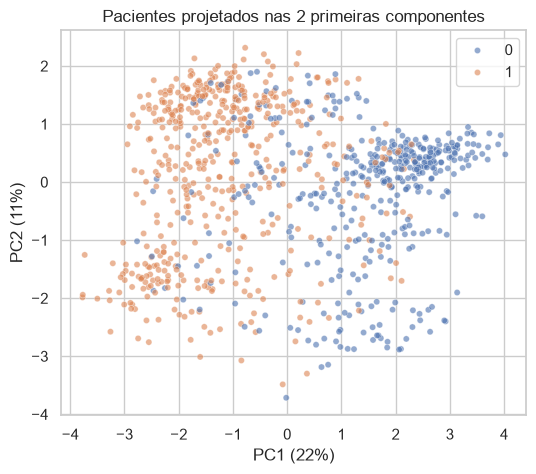

In [ ]:
X_pca = StandardScaler().fit_transform(df_enc.drop(columns=TARGET).fillna(df_enc["Cholesterol"].median()))
pca2 = PCA(n_components=2).fit(X_pca)
Z = pca2.transform(X_pca)
plt.figure(figsize=(6, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df_enc[TARGET].values, alpha=0.6, s=20)
plt.xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})")
plt.ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")
plt.title("Pacientes projetados nas 2 primeiras componentes")
salvar("08_pca_2d")
plt.show()

**Leitura (multivariada):**
- Os atributos do teste de esforço andam juntos: `ST_Slope_Up` × `ST_Slope_Flat` (as duas categorias são quase
  complementares), `ExerciseAngina` × `Oldpeak`, `MaxHR` inversamente com idade e com angina.
- No VIF, só `ST_Slope_Up` (5,5) e `ST_Slope_Flat` (4,5) chegam perto de 5 — esperado, são categorias quase
  complementares da mesma variável (quem não é Up quase sempre é Flat). Todo o resto fica abaixo de 2: há
  redundância parcial, mas não colinearidade grave. Isso explica por que a seleção de atributos não deve ganhar muita acurácia, mas pode simplificar o modelo.
- Na projeção PCA, as duas classes já aparecem **razoavelmente separadas na PC1**, com uma zona de sobreposição no
  meio → espera-se um problema **quase linearmente separável**, com acurácia na faixa de 85%, não 99%.

## 7. Pré-processamento
- One-hot das categóricas (`drop_first=True` para evitar a "armadilha das dummies").
- Separação **treino (80%) / teste (20%) estratificada**. O teste fica guardado até a etapa 10.
- Imputação (mediana) e padronização ficam **dentro do pipeline**, ajustadas só com o treino em cada fold.

In [ ]:
X = df_enc.drop(columns=TARGET)
y = df_enc[TARGET]
FEATURES = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Treino:", X_train.shape, " Teste:", X_test.shape)
print("Atributos após one-hot:", len(FEATURES))
print(FEATURES)

def prep():
    return [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
SCORING = ["accuracy", "roc_auc", "recall", "f1"]

def avaliar_cv(pipe, X_, y_=None):
    y_ = y_train if y_ is None else y_
    r = cross_validate(pipe, X_, y_, cv=CV, scoring=SCORING, n_jobs=-1)
    return {m: r[f"test_{m}"].mean() for m in SCORING} | {"auc_std": r["test_roc_auc"].std()}

Treino: (733, 15)  Teste: (184, 15)
Atributos após one-hot: 15
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


## 8. Seleção / redução de atributos

Testamos as três famílias clássicas de seleção e uma de redução:

| Família | Método | Ideia |
|---|---|---|
| **Filtro** | ANOVA F (`f_classif`) e Informação Mútua | Ranqueia cada atributo isoladamente pela relação com o alvo |
| **Wrapper** | RFE / RFECV com Regressão Logística | Treina o modelo e remove o pior atributo, repetidamente |
| **Embutido** | Regressão Logística com penalização L1 (Lasso) | A própria penalização zera os coeficientes inúteis |
| **Redução** | PCA | Cria novas variáveis (componentes) combinando as originais |

Toda a seleção é feita **somente no treino**.

### 8.1 Filtro — ANOVA F e Informação Mútua

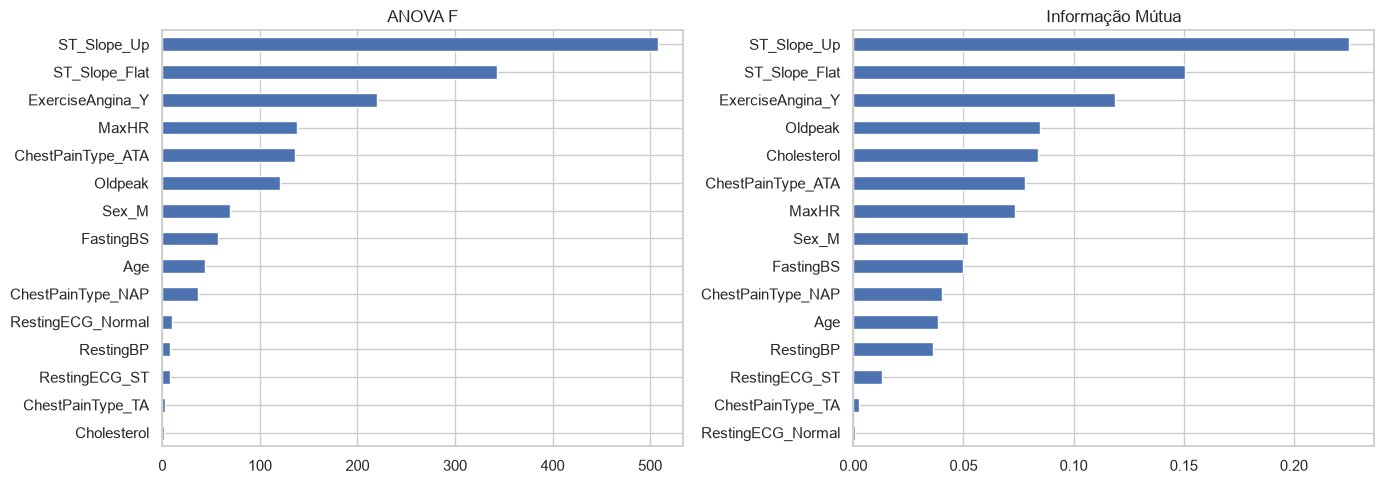

,ANOVA F,p-valor,Info. Mútua
ST_Slope_Up,508.3189,0.0000,0.2251
ST_Slope_Flat,343.3440,0.0000,0.1506
ExerciseAngina_Y,220.2591,0.0000,0.1186
MaxHR,138.3855,0.0000,0.0736
ChestPainType_ATA,136.1639,0.0000,0.0777
Oldpeak,120.5973,0.0000,0.0849
Sex_M,69.4925,0.0000,0.0519
FastingBS,57.1813,0.0000,0.0499
Age,43.5459,0.0000,0.0383
ChestPainType_NAP,36.8250,0.0000,0.0402


In [ ]:
X_tr_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train), columns=FEATURES)

f_scores, f_p = f_classif(X_tr_imp, y_train)
mi = mutual_info_classif(X_tr_imp, y_train, random_state=RANDOM_STATE)
filtro = pd.DataFrame({"ANOVA F": f_scores, "p-valor": f_p, "Info. Mútua": mi}, index=FEATURES)
filtro = filtro.sort_values("ANOVA F", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
filtro["ANOVA F"].plot.barh(ax=axes[0]).invert_yaxis()
axes[0].set_title("ANOVA F")
filtro["Info. Mútua"].sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Informação Mútua")
plt.tight_layout()
salvar("09_filtro")
plt.show()
filtro.round(4)

**Quantos atributos manter?** Variamos *k* (os *k* melhores pelo ANOVA) e medimos a AUC por validação cruzada.

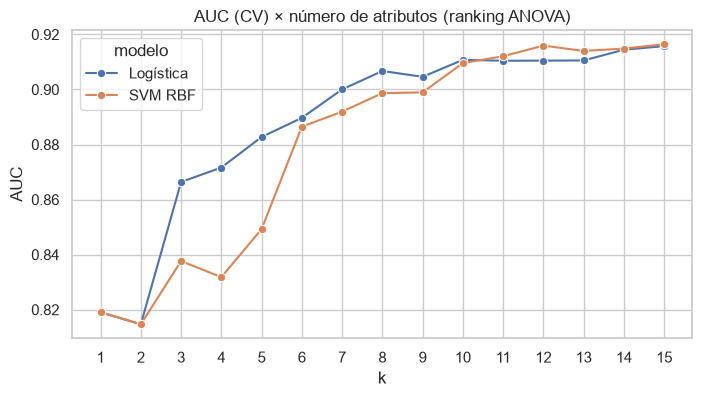

k,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
modelo,,,,,,,,,,,,,,,
Logística,0.819,0.8147,0.8664,0.8716,0.8827,0.8897,0.9000,0.9067,0.9046,0.9108,0.9104,0.9105,0.9105,0.9144,0.9158
SVM RBF,0.819,0.8147,0.8376,0.8318,0.8493,0.8865,0.8919,0.8987,0.8990,0.9096,0.9121,0.9159,0.9140,0.9149,0.9164


In [ ]:
curva = []
for k in range(1, len(FEATURES) + 1):
    for nome, clf in [("Logística", LogisticRegression(max_iter=1000)), ("SVM RBF", SVC())]:
        pipe = Pipeline(prep() + [("sel", SelectKBest(f_classif, k=k)), ("clf", clf)])
        r = cross_validate(pipe, X_train, y_train, scoring="roc_auc",
                           cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
        curva.append({"k": k, "modelo": nome, "AUC": r["test_score"].mean()})
curva = pd.DataFrame(curva)

plt.figure(figsize=(8, 4))
sns.lineplot(data=curva, x="k", y="AUC", hue="modelo", marker="o")
plt.title("AUC (CV) × número de atributos (ranking ANOVA)")
plt.xticks(range(1, len(FEATURES) + 1))
salvar("10_curva_k")
plt.show()
curva.pivot(index="k", columns="modelo", values="AUC").round(4).T

A curva mostra **retornos decrescentes**: com os 3 melhores atributos (`ST_Slope_Up`, `ST_Slope_Flat`,
`ExerciseAngina_Y`) já se chega a AUC ≈ 0,87; a partir de ~10 atributos a curva praticamente estabiliza.

### 8.2 Wrapper — RFECV com Regressão Logística

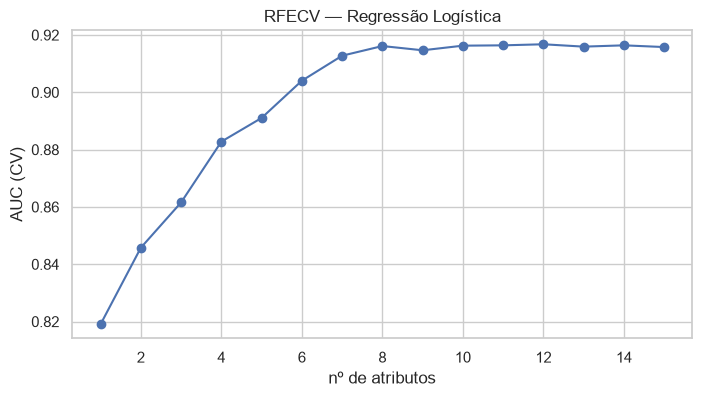

Nº ótimo de atributos (RFECV): 12
Selecionados: ['FastingBS', 'Sex_M', 'Oldpeak', 'MaxHR', 'ChestPainType_ATA', 'RestingECG_Normal', 'ChestPainType_TA', 'ChestPainType_NAP', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'RestingECG_ST']


In [ ]:
rfecv = RFECV(LogisticRegression(max_iter=1000), step=1, scoring="roc_auc",
              cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), min_features_to_select=1)
rfecv.fit(StandardScaler().fit_transform(X_tr_imp), y_train)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(FEATURES) + 1), rfecv.cv_results_["mean_test_score"], marker="o")
plt.xlabel("nº de atributos"); plt.ylabel("AUC (CV)"); plt.title("RFECV — Regressão Logística")
salvar("11_rfecv")
plt.show()

rfe_rank = pd.Series(rfecv.ranking_, index=FEATURES).sort_values()
print("Nº ótimo de atributos (RFECV):", rfecv.n_features_)
print("Selecionados:", rfe_rank[rfe_rank == 1].index.tolist())

### 8.3 Embutido — Regressão Logística L1 (Lasso)
Quanto mais forte a penalização (menor `C`), mais coeficientes vão a zero. Escolhemos `C` por validação cruzada.

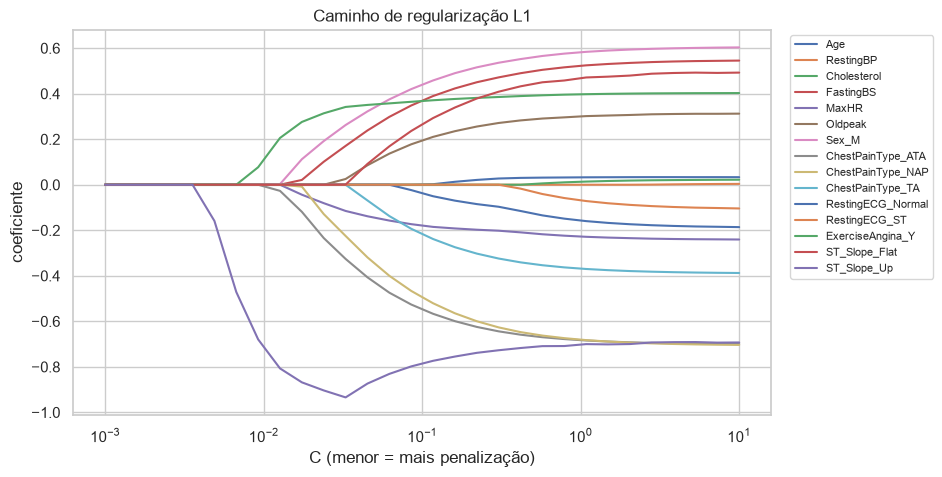

Melhor C: 0.5736
Zerados pelo L1: ['RestingBP']


ST_Slope_Up         -0.713
ChestPainType_ATA   -0.670
ChestPainType_NAP   -0.663
Sex_M                0.566
FastingBS            0.505
ST_Slope_Flat        0.446
ExerciseAngina_Y     0.393
ChestPainType_TA    -0.354
Oldpeak              0.290
MaxHR               -0.218
RestingECG_Normal   -0.135
RestingECG_ST       -0.041
Age                  0.031
Cholesterol          0.006
RestingBP            0.000
dtype: float64

In [ ]:
Xs = StandardScaler().fit_transform(X_tr_imp)
Cs = np.logspace(-3, 1, 30)
coefs = np.array([LogisticRegression(penalty="l1", solver="liblinear", C=c).fit(Xs, y_train).coef_[0] for c in Cs])

plt.figure(figsize=(9, 5))
for j, f in enumerate(FEATURES):
    plt.plot(Cs, coefs[:, j], label=f)
plt.xscale("log"); plt.xlabel("C (menor = mais penalização)"); plt.ylabel("coeficiente")
plt.title("Caminho de regularização L1")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
salvar("12_lasso_path")
plt.show()

gs_l1 = GridSearchCV(LogisticRegression(penalty="l1", solver="liblinear"), {"C": Cs}, scoring="roc_auc",
                     cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)).fit(Xs, y_train)
coef_l1 = pd.Series(gs_l1.best_estimator_.coef_[0], index=FEATURES)
print("Melhor C:", round(gs_l1.best_params_["C"], 4))
print("Zerados pelo L1:", coef_l1[coef_l1 == 0].index.tolist())
coef_l1.sort_values(key=abs, ascending=False).round(3)

### 8.4 Redução — PCA

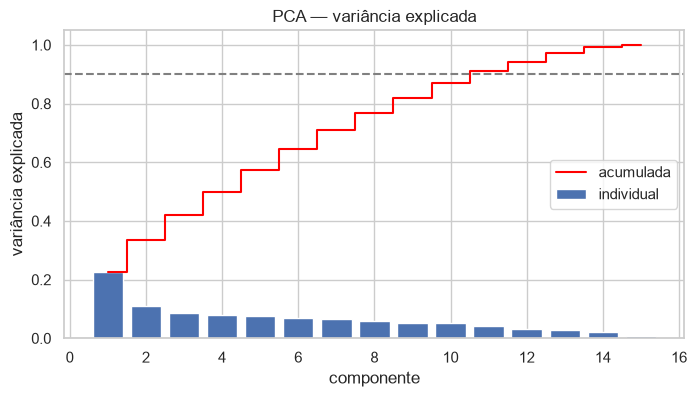

Componentes para 90% da variância: 11 (de 15)


In [ ]:
pca_full = PCA().fit(Xs)
acum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(8, 4))
plt.bar(range(1, len(acum) + 1), pca_full.explained_variance_ratio_, label="individual")
plt.step(range(1, len(acum) + 1), acum, where="mid", color="red", label="acumulada")
plt.axhline(0.9, ls="--", color="gray")
plt.xlabel("componente"); plt.ylabel("variância explicada"); plt.legend()
plt.title("PCA — variância explicada")
salvar("13_pca_variancia")
plt.show()
N_PCA = int(np.argmax(acum >= 0.9) + 1)
print(f"Componentes para 90% da variância: {N_PCA} (de {len(FEATURES)})")

### 8.5 Comparação dos métodos
Cada estratégia é colocada **dentro do pipeline** e avaliada com validação cruzada repetida (5 folds × 10 repetições),
para os dois classificadores. Assim a seleção é refeita em cada fold e não há vazamento de informação.

In [ ]:
# Regra da parcimônia: menor k cuja AUC média fica a até 0,01 da melhor
auc_k = curva.groupby("k")["AUC"].mean()
K_FILTRO = int(auc_k[auc_k >= auc_k.max() - 0.01].index.min())
print("k escolhido pelo filtro:", K_FILTRO, "->", filtro.index[:K_FILTRO].tolist())

seletores = {
    "Todos os atributos": [],
    f"Filtro ANOVA (k={K_FILTRO})": [("sel", SelectKBest(f_classif, k=K_FILTRO))],
    f"Wrapper RFE (k={rfecv.n_features_})": [("sel", RFE(LogisticRegression(max_iter=1000), n_features_to_select=rfecv.n_features_))],
    "Embutido L1": [("sel", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", C=gs_l1.best_params_["C"])))],
    f"PCA ({N_PCA} comp.)": [("sel", PCA(n_components=N_PCA))],
}
clfs = {"Logística": LogisticRegression(max_iter=1000), "SVM RBF": SVC()}

comp = []
for s_nome, s_steps in seletores.items():
    for c_nome, clf in clfs.items():
        r = avaliar_cv(Pipeline(prep() + s_steps + [("clf", clf)]), X_train)
        comp.append({"seleção": s_nome, "modelo": c_nome} | r)
comp = pd.DataFrame(comp)
comp.pivot(index="seleção", columns="modelo", values=["roc_auc", "accuracy"]).round(4)

k escolhido pelo filtro: 10 -> ['ST_Slope_Up', 'ST_Slope_Flat', 'ExerciseAngina_Y', 'MaxHR', 'ChestPainType_ATA', 'Oldpeak', 'Sex_M', 'FastingBS', 'Age', 'ChestPainType_NAP']


roc_auc          accuracy        
modelo              Logística SVM RBF Logística SVM RBF
seleção                                                
Embutido L1            0.9158  0.9154    0.8490  0.8548
Filtro ANOVA (k=10)    0.9134  0.9093    0.8513  0.8569
PCA (11 comp.)         0.9123  0.9142    0.8535  0.8600
Todos os atributos     0.9158  0.9158    0.8491  0.8551
Wrapper RFE (k=12)     0.9168  0.9139    0.8490  0.8540

### 8.6 Escolha final dos atributos

**Resultado:** todos os métodos ficaram empatados (AUC ≈ 0,91–0,92, diferenças menores que o desvio-padrão entre
folds). A seleção **não melhora** a performance — o que já era esperado pela análise multivariada (pouca
redundância, VIFs baixos). Então o critério de desempate é **simplicidade e interpretabilidade**.

**Escolha: os 12 atributos do RFE (Wrapper)**, que removem `Age`, `RestingBP` e `Cholesterol`. Motivos:
1. **Consenso entre métodos:** o L1 zerou `RestingBP` e deu coeficientes quase nulos para `Age` e `Cholesterol`;
   o filtro ANOVA coloca `RestingBP` e `Cholesterol` entre os piores; e na Logística do `statsmodels` com todos os
   atributos, os três têm p-valor > 0,8 (nenhum efeito detectável).
2. **Mesma performance** que usar tudo (AUC 0,917 vs 0,916), com 20% menos variáveis.
3. **Mantém os atributos originais** — o PCA empatou, mas suas componentes são combinações de tudo e não dá para
   explicar o modelo para um médico.
4. **Bônus prático:** sai o `Cholesterol`, a variável com 19% de dados imputados (e com o artefato de coleta).

**Por que a idade sai, se ela é significativa sozinha?** Porque a informação dela já está nos outros atributos: pacientes
mais velhos têm `MaxHR` menor, mais angina e mais alterações no ST. Dado o teste de esforço, a idade não acrescenta nada —
um exemplo clássico de efeito que aparece na análise bivariada e some na multivariada.

In [ ]:
FINAL = rfe_rank[rfe_rank == 1].index.tolist()
print(len(FINAL), "atributos finais:", FINAL)
print("Removidos:", [f for f in FEATURES if f not in FINAL])

12 atributos finais: ['FastingBS', 'Sex_M', 'Oldpeak', 'MaxHR', 'ChestPainType_ATA', 'RestingECG_Normal', 'ChestPainType_TA', 'ChestPainType_NAP', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up', 'RestingECG_ST']
Removidos: ['Age', 'RestingBP', 'Cholesterol']


## 9. Modelos supervisionados

### 9.1 Regressão Linear (como classificador — "modelo de probabilidade linear")
A Regressão Linear prevê um número contínuo. Usamos ela para prever `HeartDisease` (0/1) e cortamos em 0,5,
para mostrar **por que ela não é a ferramenta adequada** para classificação.

R² no teste: 0.568
Previsões fora de [0, 1]: 30 de 184
Faixa das previsões: [-0.13, 1.15]
Acurácia com corte em 0,5: 0.875


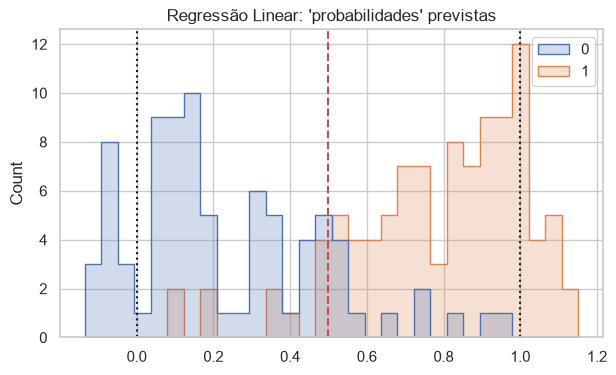

In [ ]:
lin = Pipeline(prep() + [("clf", LinearRegression())]).fit(X_train[FINAL], y_train)
pred_lin = lin.predict(X_test[FINAL])
print(f"R² no teste: {r2_score(y_test, pred_lin):.3f}")
print(f"Previsões fora de [0, 1]: {((pred_lin < 0) | (pred_lin > 1)).sum()} de {len(pred_lin)}")
print(f"Faixa das previsões: [{pred_lin.min():.2f}, {pred_lin.max():.2f}]")
print(f"Acurácia com corte em 0,5: {accuracy_score(y_test, pred_lin >= 0.5):.3f}")

plt.figure(figsize=(7, 4))
sns.histplot(x=pred_lin, hue=y_test.values, bins=30, element="step")
plt.axvline(0, color="k", ls=":"); plt.axvline(1, color="k", ls=":"); plt.axvline(0.5, color="r", ls="--")
plt.title("Regressão Linear: 'probabilidades' previstas")
salvar("14_regressao_linear")
plt.show()

**Leitura:** surpreendentemente, a Regressão Linear acerta **87,5%** com o corte em 0,5 — porque as classes são
quase linearmente separáveis (vimos no PCA). Mas ela **não é um classificador adequado**:
- 30 dos 184 pacientes recebem "probabilidade" **fora de [0, 1]** (de −0,13 a 1,15), o que não tem interpretação;
- o R² de 0,57 mede o ajuste a uma variável 0/1, o que não faz muito sentido;
- os resíduos não são normais nem têm variância constante (o alvo só assume dois valores), violando as hipóteses do modelo.

A **Regressão Logística** resolve isso passando a combinação linear pela função sigmoide: a saída vira uma
probabilidade de verdade, entre 0 e 1.

### 9.2 Regressão Logística — interpretação estatística (statsmodels)
Ajustamos a Logística no treino com `statsmodels` para ler **coeficientes, p-valores e odds ratios**.
Os atributos numéricos estão padronizados: o odds ratio é o efeito de **+1 desvio-padrão**.

In [ ]:
X_sm = pd.DataFrame(Pipeline(prep()).fit_transform(X_train[FINAL]), columns=FINAL, index=X_train.index)
logit = sm.Logit(y_train, sm.add_constant(X_sm)).fit(disp=0)
print(logit.summary2().tables[0].iloc[:, :2].to_string(header=False))
tab = pd.DataFrame({"coef": logit.params, "p-valor": logit.pvalues, "odds ratio": np.exp(logit.params),
                    "OR IC95% inf": np.exp(logit.conf_int()[0]), "OR IC95% sup": np.exp(logit.conf_int()[1])})
tab.drop("const").sort_values("odds ratio", ascending=False).round(3)

0               Model:             Logit
1  Dependent Variable:      HeartDisease
2                Date:  2026-10-14 17:49
3    No. Observations:               733
4            Df Model:                12
5        Df Residuals:               720
6           Converged:            1.0000
7      No. Iterations:            7.0000


,coef,p-valor,odds ratio,OR IC95% inf,OR IC95% sup
Sex_M,0.599,0.000,1.820,1.427,2.320
FastingBS,0.553,0.000,1.738,1.357,2.226
ST_Slope_Flat,0.497,0.056,1.643,0.987,2.736
ExerciseAngina_Y,0.407,0.001,1.503,1.169,1.932
Oldpeak,0.318,0.018,1.374,1.055,1.789
RestingECG_ST,-0.115,0.436,0.891,0.668,1.190
RestingECG_Normal,-0.204,0.145,0.816,0.621,1.073
MaxHR,-0.253,0.053,0.776,0.601,1.003
ChestPainType_TA,-0.390,0.000,0.677,0.553,0.829
ST_Slope_Up,-0.693,0.012,0.500,0.292,0.856


**Leitura dos odds ratios (OR):** OR > 1 aumenta a chance de doença, OR < 1 diminui.
- **Homem:** 1,8× a chance de doença em relação a mulher, mantidos os demais atributos.
- **Glicemia de jejum alta (`FastingBS`):** 1,7× — diabetes é fator de risco cardiovascular conhecido.
- **Angina no exercício:** 1,5×; **Oldpeak** (+1 desvio-padrão): 1,4×.
- **Dor do tipo ATA/NAP/TA:** reduzem a chance pela metade em relação ao paciente **assintomático (ASY)**, que é a
  categoria de referência. Ou seja: ter dor "típica" é sinal **melhor** do que não sentir nada.
- **ST_Slope Up** (curva normal no esforço) reduz a chance pela metade em relação a `Down`.
- `RestingECG` não é significativo (p > 0,1): o ECG **em repouso** quase não ajuda; o que discrimina é o
  comportamento do coração **no esforço**.

### 9.3 Ajuste de hiperparâmetros — Logística, SVM linear e SVM RBF
`GridSearchCV` com validação cruzada estratificada (5 folds) no treino, otimizando a AUC.

In [ ]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    "Regressão Logística": (LogisticRegression(max_iter=1000),
                            {"clf__C": np.logspace(-3, 2, 12)}),
    "SVM Linear": (SVC(kernel="linear", probability=True, random_state=RANDOM_STATE),
                   {"clf__C": np.logspace(-3, 1, 9)}),
    "SVM RBF": (SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
                {"clf__C": [0.1, 0.3, 1, 3, 10, 30], "clf__gamma": ["scale", 0.003, 0.01, 0.03, 0.1, 0.3]}),
}
modelos = {}
for nome, (clf, grid) in grids.items():
    gs = GridSearchCV(Pipeline(prep() + [("clf", clf)]), grid, scoring="roc_auc", cv=cv5, n_jobs=-1)
    gs.fit(X_train[FINAL], y_train)
    modelos[nome] = gs.best_estimator_
    print(f"{nome:22s} melhor AUC (CV) = {gs.best_score_:.4f}  params = {gs.best_params_}")

Regressão Logística    melhor AUC (CV) = 0.9185  params = {'clf__C': np.float64(0.1873817422860383)}


SVM Linear             melhor AUC (CV) = 0.9148  params = {'clf__C': np.float64(1.0)}


SVM RBF                melhor AUC (CV) = 0.9222  params = {'clf__C': 10, 'clf__gamma': 0.01}


### 9.4 Comparação por validação cruzada repetida (treino)

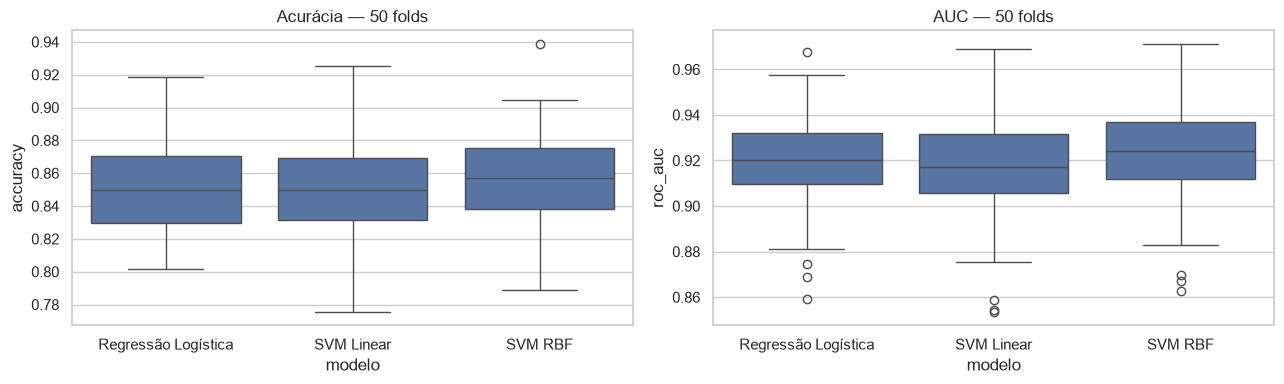

accuracy         roc_auc          recall              f1  \
                        mean     std    mean     std    mean     std    mean   
modelo                                                                         
Regressão Logística   0.8517  0.0276  0.9192  0.0226  0.8793  0.0296  0.8677   
SVM Linear            0.8491  0.0297  0.9160  0.0246  0.8778  0.0356  0.8654   
SVM RBF               0.8572  0.0280  0.9226  0.0230  0.8941  0.0270  0.8739   

                             
                        std  
modelo                       
Regressão Logística  0.0235  
SVM Linear           0.0258  
SVM RBF              0.0231

In [ ]:
res_cv = []
for nome, m in modelos.items():
    r = cross_validate(m, X_train[FINAL], y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    for i in range(len(r["test_roc_auc"])):
        res_cv.append({"modelo": nome} | {m_: r[f"test_{m_}"][i] for m_ in SCORING})
res_cv = pd.DataFrame(res_cv)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=res_cv, x="modelo", y="accuracy", ax=axes[0]); axes[0].set_title("Acurácia — 50 folds")
sns.boxplot(data=res_cv, x="modelo", y="roc_auc", ax=axes[1]); axes[1].set_title("AUC — 50 folds")
plt.tight_layout()
salvar("15_cv_modelos")
plt.show()
res_cv.groupby("modelo").agg(["mean", "std"]).round(4)

In [ ]:
# Os modelos diferem de verdade? Teste de Wilcoxon pareado nas AUCs dos mesmos folds
a = res_cv[res_cv.modelo == "Regressão Logística"]["roc_auc"].values
for outro in ["SVM Linear", "SVM RBF"]:
    b = res_cv[res_cv.modelo == outro]["roc_auc"].values
    print(f"Logística vs {outro}: diferença média de AUC = {(b - a).mean():+.4f}, "
          f"p-valor Wilcoxon = {stats.wilcoxon(a, b).pvalue:.4f}")

Logística vs SVM Linear: diferença média de AUC = -0.0032, p-valor Wilcoxon = 0.0010
Logística vs SVM RBF: diferença média de AUC = +0.0035, p-valor Wilcoxon = 0.0065


**Leitura:** os três modelos ficam com AUC entre 0,916 e 0,923 e acurácia ~85%. As diferenças (≤ 0,007 de AUC)
são **muito menores que o desvio-padrão entre folds (~0,023)**. O Wilcoxon acusa diferença "significativa",
mas os folds de uma validação repetida não são independentes, o que infla a significância — na prática, os
modelos são **equivalentes**.

O SVM RBF escolheu `gamma = 0,01`, um valor pequeno, que deixa a fronteira de decisão **quase linear**. Ou seja,
o modelo mais flexível chegou sozinho à conclusão de que o problema é praticamente linear — por isso não supera a
Logística.

## 10. Avaliação no conjunto de teste (dados nunca vistos)

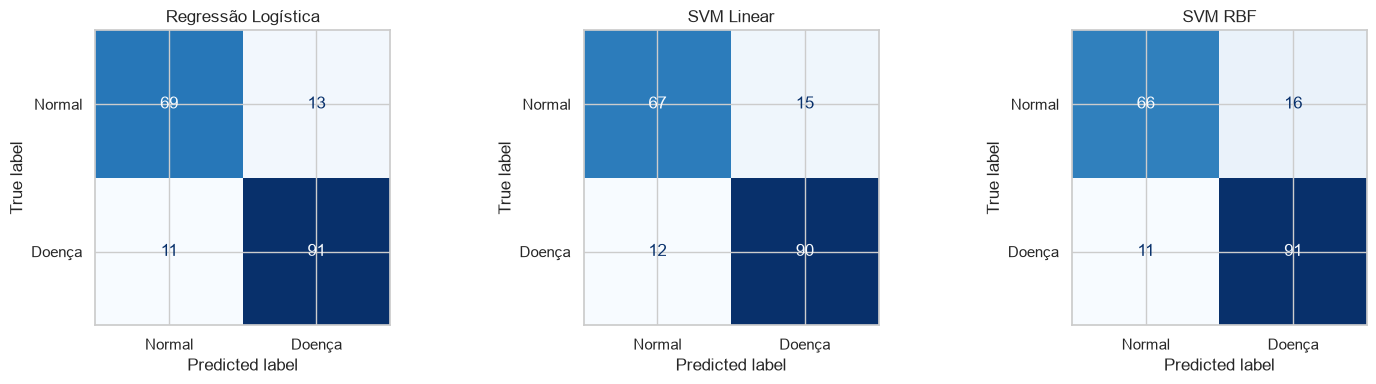

,acurácia,precisão,recall,F1,AUC
modelo,,,,,
Regressão Logística,0.8696,0.8750,0.8922,0.8835,0.9365
SVM Linear,0.8533,0.8571,0.8824,0.8696,0.9360
SVM RBF,0.8533,0.8505,0.8922,0.8708,0.9354


In [ ]:
linhas = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nome, m) in zip(axes, modelos.items()):
    pred = m.predict(X_test[FINAL])
    proba = m.predict_proba(X_test[FINAL])[:, 1]
    linhas.append({"modelo": nome, "acurácia": accuracy_score(y_test, pred),
                   "precisão": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                   "F1": f1_score(y_test, pred), "AUC": roc_auc_score(y_test, proba)})
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Normal", "Doença"], ax=ax,
                                            colorbar=False, cmap="Blues")
    ax.set_title(nome)
plt.tight_layout()
salvar("16_matrizes_confusao")
plt.show()
res_teste = pd.DataFrame(linhas).set_index("modelo")
res_teste.round(4)

**Leitura:** no teste, a **Regressão Logística** fica à frente (acurácia 87%, recall 89%, AUC 0,94), com os SVMs
logo atrás (85%). Com 184 pacientes no teste, a diferença equivale a **3 pacientes** — de novo, empate técnico.
A AUC no teste (~0,94) é até um pouco maior que na validação cruzada (~0,92), o que indica que **não houve
overfitting**: a partição de teste foi apenas um pouco "mais fácil".

**Modelo escolhido: Regressão Logística** — desempenho equivalente ao melhor, é o mais simples, é rápido e,
principalmente, é **interpretável** (odds ratios), o que importa muito em saúde.

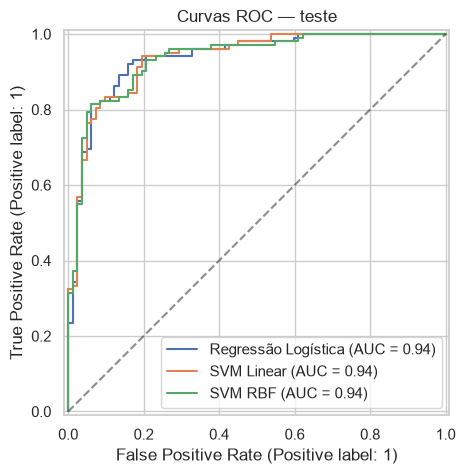

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
for nome, m in modelos.items():
    RocCurveDisplay.from_estimator(m, X_test[FINAL], y_test, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_title("Curvas ROC — teste")
salvar("17_roc")
plt.show()

In [ ]:
best = modelos["Regressão Logística"]
print(classification_report(y_test, best.predict(X_test[FINAL]), target_names=["Normal", "Doença"]))

              precision    recall  f1-score   support

      Normal       0.86      0.84      0.85        82
      Doença       0.88      0.89      0.88       102

    accuracy                           0.87       184
   macro avg       0.87      0.87      0.87       184
weighted avg       0.87      0.87      0.87       184



### 10.1 Análise de erros — quem o modelo erra?

In [ ]:
teste = X_test.copy()
teste["real"] = y_test
teste["proba"] = best.predict_proba(X_test[FINAL])[:, 1]
teste["pred"] = (teste["proba"] >= 0.5).astype(int)
teste["erro"] = np.select([(teste.real == 1) & (teste.pred == 0), (teste.real == 0) & (teste.pred == 1)],
                          ["Falso negativo", "Falso positivo"], "Acerto")
print(teste["erro"].value_counts())
teste.groupby("erro")[["Age", "MaxHR", "Oldpeak", "ST_Slope_Flat", "ExerciseAngina_Y", "Sex_M"]].mean().round(2)

erro
Acerto            160
Falso positivo     13
Falso negativo     11
Name: count, dtype: int64


,Age,MaxHR,Oldpeak,ST_Slope_Flat,ExerciseAngina_Y,Sex_M
erro,,,,,,
Acerto,52.62,136.66,0.96,0.49,0.43,0.77
Falso negativo,52.91,151.09,0.84,0.36,0.09,0.82
Falso positivo,50.15,130.23,0.96,0.46,0.46,0.77


**Quem o modelo erra?** Os **falsos negativos** (doentes classificados como saudáveis) têm um perfil de "teste de
esforço bom": `MaxHR` alta (151 vs 137 de média), quase nunca têm angina no exercício (9% vs 43%) e menos `ST_Slope`
Flat. São doentes que **parecem saudáveis nos dados disponíveis** — provavelmente seriam detectados só com exames que
a base não tem (cateterismo, ecocardiograma, troponina). Esse é o limite da informação da base, e não do modelo.

### 10.2 Ajuste do limiar de decisão
Em triagem médica, um **falso negativo** (mandar para casa um doente) é pior que um falso positivo (pedir mais
exames). Podemos baixar o limiar de 0,5 para aumentar o *recall*. O limiar é escolhido com previsões de
**validação cruzada no treino**, e só depois aplicado no teste.

In [ ]:
from sklearn.model_selection import cross_val_predict
proba_oof = cross_val_predict(best, X_train[FINAL], y_train, cv=cv5, method="predict_proba")[:, 1]
lims = np.arange(0.2, 0.65, 0.05)
tab_lim = pd.DataFrame([{"limiar": t, "recall": recall_score(y_train, proba_oof >= t),
                         "precisão": precision_score(y_train, proba_oof >= t),
                         "acurácia": accuracy_score(y_train, proba_oof >= t)} for t in lims]).round(3)
tab_lim

,limiar,recall,precisão,acurácia
0,0.20,0.970,0.757,0.812
1,0.25,0.963,0.785,0.834
2,0.30,0.946,0.805,0.843
3,0.35,0.923,0.820,0.846
4,0.40,0.906,0.834,0.849
5,0.45,0.896,0.848,0.854
6,0.50,0.881,0.854,0.851
7,0.55,0.847,0.853,0.835
8,0.60,0.830,0.862,0.832


Escolhemos **limiar = 0,35**: na validação cruzada, o recall sobe de 88% para 92%, custando ~3 pontos de precisão
e quase nada de acurácia. Para uma ferramenta de **triagem**, essa troca vale a pena.

limiar 0.50 -> acurácia 0.870 | recall 0.892 | precisão 0.875 | falsos negativos 11
limiar 0.35 -> acurácia 0.875 | recall 0.941 | precisão 0.850 | falsos negativos 6


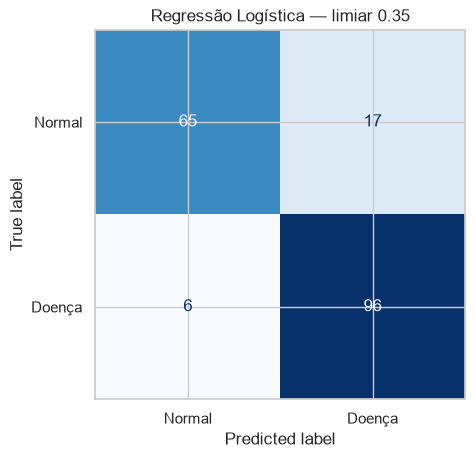

In [ ]:
LIMIAR = 0.35
proba_te = best.predict_proba(X_test[FINAL])[:, 1]
for t in [0.5, LIMIAR]:
    p = (proba_te >= t).astype(int)
    print(f"limiar {t:.2f} -> acurácia {accuracy_score(y_test, p):.3f} | recall {recall_score(y_test, p):.3f} | "
          f"precisão {precision_score(y_test, p):.3f} | falsos negativos {((p == 0) & (y_test == 1)).sum()}")
ConfusionMatrixDisplay.from_predictions(y_test, (proba_te >= LIMIAR).astype(int), display_labels=["Normal", "Doença"],
                                        colorbar=False, cmap="Blues")
plt.title(f"Regressão Logística — limiar {LIMIAR}")
salvar("18_matriz_limiar")
plt.show()

No teste, o limiar 0,35 **reduz os falsos negativos de 11 para 6** (recall 89% → 94%), sem perder acurácia.

## 11. Conclusões

**Sobre a base**
- Base pequena (917 pacientes após a limpeza), balanceada e quase limpa — o único problema sério foram os
  **zeros impossíveis** em `Cholesterol` (19%), que eram dados faltantes e ainda carregavam um **artefato de coleta**
  (88% desses pacientes eram doentes porque vieram quase todos de uma mesma base de origem).
- O que mais discrimina a doença é o **teste de esforço** (`ST_Slope`, angina no exercício, `Oldpeak`, `MaxHR`) e o
  **tipo de dor no peito** — e não os fatores de risco "famosos" como colesterol e pressão, que quase não ajudam aqui.
- Insights contraintuitivos: o paciente **assintomático** é o de maior risco; a **idade** é significativa sozinha,
  mas some quando os dados do teste de esforço entram no modelo.

**Sobre a seleção de atributos**
- Filtro, wrapper, embutido e PCA **empataram**. A seleção não aumentou a performance (os atributos têm pouca
  redundância), mas permitiu **remover 3 de 15 variáveis** (`Age`, `RestingBP`, `Cholesterol`) sem perda nenhuma.

**Sobre os modelos**
- Regressão Logística, SVM linear e SVM RBF ficaram **equivalentes** (AUC ≈ 0,92 na CV; 0,94 no teste;
  acurácia 85–87%). O problema é praticamente linear, então o kernel RBF não tem o que ganhar.
- A Regressão Linear "funciona" como classificador (87,5%), mas gera probabilidades fora de [0, 1] — inadequada.
- **Modelo final:** Regressão Logística com 12 atributos e limiar 0,35 → **recall de 94%** e acurácia de 87,5% no teste.

**Por que os resultados foram bons?** Os atributos do teste de esforço são fortemente ligados ao diagnóstico, as
classes são balanceadas e quase linearmente separáveis.

**Por que não foram melhores (por que não 99%)?**
- ~15% dos pacientes ficam numa zona de sobreposição: doentes com teste de esforço normal e saudáveis com teste
  alterado. Os dados disponíveis simplesmente não separam esses casos.
- A base é pequena e junta **5 hospitais diferentes**, com protocolos e populações diferentes (e sem a coluna de
  origem para controlar isso).
- Base 79% masculina → o modelo deve ser validado em mulheres antes de qualquer uso real.
- Faltam exames decisivos (angiografia, ecocardiograma, marcadores sanguíneos).